# Lesson 06 - Tuning and model selection

The defaults are a sensible start, not the best possible. **Tuning** means trying settings and keeping what
works, *without fooling yourself*. The rules:

1. **Judge only on validation.** The test set is opened once, at the very end.
2. **Change one thing at a time**, so you know what made the difference.
3. **Tune in order of impact:** learning rate, then augmentation and regularisation, then the architecture
   (backbone). Batch size mostly affects speed; set it by memory.
4. **Expect noise.** Two runs with different seeds differ by a point or two. Don't celebrate a 0.5-point win.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import math
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as Fn
import data as D
from device import auto_batch_size, pick_device
from labels import CLASSES
from models import ShipNet
from paths import DATA_DIR, RUNS_DIR

mel, table = D.open_features(DATA_DIR)
dev = pick_device()

D:\shipsound\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Learning-rate range test

A quick way to find a good learning rate: train for a few hundred batches while **raising the learning rate
exponentially** from tiny to huge, and record the loss. The loss falls, flattens, then explodes. A good learning
rate sits where the loss is still falling steeply, roughly 10x below the minimum.

On a CPU-only machine, set `BACKBONE = "tiny_cnn"` and `STEPS = 100` to keep it quick.

300 steps in 35 s


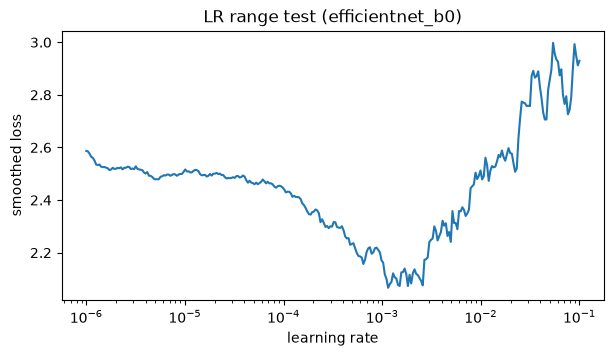

lowest loss at lr = 1.1e-03 -> try about 10x lower for training


In [2]:
BACKBONE = "efficientnet_b0" if dev.type != "cpu" else "tiny_cnn"
STEPS, LR_MIN, LR_MAX = 300 if dev.type != "cpu" else 100, 1e-6, 1e-1

rows = D.select_rows(table, fold=1, split="train", task="class")
norm = D.compute_norm(mel, rows, max_clips=500)
amp = dev.type == "cuda"                          # 16-bit maths on NVIDIA GPUs, like train.py (saves memory)
loader = torch.utils.data.DataLoader(D.MelDataset(DATA_DIR, table, rows, CLASSES, norm, augment=True),
                                     batch_size=max(8, auto_batch_size(BACKBONE, dev) // 2), shuffle=True)
model = ShipNet(BACKBONE, len(CLASSES), pretrained=BACKBONE != "tiny_cnn").to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=LR_MIN)
scaler = torch.amp.GradScaler("cuda", enabled=amp)
lrs, losses, smooth = [], [], None
it = iter(loader)
t0 = time.time()
for step in range(STEPS):
    lr = LR_MIN * (LR_MAX / LR_MIN) ** (step / (STEPS - 1))
    for g in opt.param_groups:
        g["lr"] = lr
    b = next(it)
    with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
        loss = Fn.cross_entropy(model(b["x"].to(dev))["logits"].float(), b["y_class"].to(dev))
    opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()
    lrs.append(lr); losses.append(smooth)
    if smooth > 4 * min(losses):
        break
print(f"{len(lrs)} steps in {time.time() - t0:.0f} s")
plt.figure(figsize=(7, 3.5)); plt.semilogx(lrs, losses)
plt.xlabel("learning rate"); plt.ylabel("smoothed loss"); plt.title(f"LR range test ({BACKBONE})"); plt.show()
print("lowest loss at lr =", f"{lrs[int(np.argmin(losses))]:.1e}", "-> try about 10x lower for training")

## 2. Small sweeps, compared on validation

Each setting is one run with its own `--name`:
```
python src/train.py --task class --lr 1e-4 --name lr_1e-4
python src/train.py --task class --lr 1e-3 --name lr_1e-3
python src/train.py --task class --backbone mobilenetv3_large_100
python src/train.py --task class --backbone resnet18
```
(The default lr 3e-4 run is `class_f1_efficientnet_b0_vessel`.) To save time while tuning, add
`--epochs 10`; the ranking between settings usually shows early.

The cell below collects **every** run in `runs/` into one table, sorted by best validation score.

In [3]:
def runs_table():
    rows = []
    for cfg_path in sorted(RUNS_DIR.glob("*/config.json")):
        run = cfg_path.parent
        if not (run / "log.csv").exists():
            continue
        c, log = json.loads(cfg_path.read_text()), pd.read_csv(run / "log.csv")
        best = log.val_metric.max() if c["task"] in ("class", "multi") else log.val_metric.min()
        rows.append({"run": run.name, "task": c["task"], "backbone": c["backbone"], "lr": c["lr"],
                     "split": c["split_mode"], "holdout": c["holdout"], "hyd_shift": c["hydrophone_shift"],
                     "epochs run": len(log), "best val": round(best, 4),
                     "min/epoch": round(log.seconds.mean() / 60, 1), "finished": (run / "done.json").exists()})
    return pd.DataFrame(rows)

t = runs_table()
if t.empty:
    print("no runs yet - start with:  python src/train.py --task class")
else:
    # only runs of the SAME experiment can be ranked against each other: normal fold-1 class runs
    # (leaky, holdout and hydrophone-shift runs answer other questions and are not comparable)
    same = (t.task == "class") & (t.split == "vessel") & t.holdout.isna() & ~t.hyd_shift
    display(t[same].sort_values("best val", ascending=False))

,run,task,backbone,lr,split,holdout,hyd_shift,epochs run,best val,min/epoch,finished
6,class_f1_efficientnet_b0_vessel_merged,class,efficientnet_b0,0.0003,vessel,NaN,False,10,0.4300,4.1,True
1,class_f1_efficientnet_b0_vessel,class,efficientnet_b0,0.0003,vessel,NaN,False,11,0.4250,4.0,True
7,class_f1_efficientnet_b0_vessel_reg,class,efficientnet_b0,0.0001,vessel,NaN,False,10,0.4102,3.7,True
8,class_f1_mobilenetv3_large_100_vessel,class,mobilenetv3_large_100,0.0003,vessel,NaN,False,10,0.3806,2.4,True


## 3. Choosing the backbone (model selection)

| backbone | size | notes |
|---|---|---|
| EfficientNet-B0 | 5.3 M parameters | strong accuracy for its size: our default |
| MobileNetV3-Large | 5.5 M | built for phones: fastest; one of the dataset authors' baselines |
| ResNet-18 | 11.7 M | older, simple and robust; a useful reference |

Pick the backbone with the best **validation** macro-F1. If two are within about a point, prefer the faster
one. Then run the **test** evaluation for the chosen one only.

## Try it

1. Run the LR range test with `BACKBONE = "efficientnet_b0"` on the GPU machine. Is 3e-4 in the good region?
2. Train two runs that differ only in `--seed` (0 and 1). How different are their best validation scores?
   That gap is your noise level when comparing settings.